# Parts 2–3 — Pairwise comparisons and multiple-comparisons correction

Input: `data/marketing_data.csv` (channel × day, built in `data_exploration.ipynb`).

- **Step 4:** Independent two-sample t-tests (`scipy.stats.ttest_ind`, default equal-variance Student test as the lab specifies) on daily CPA, daily conversion rate and daily ROAS, with Cohen's d for every pair.
- **Step 5:** Fisher's exact test on pooled conversions vs non-conversions (clicks) for every pair.
- **Step 6:** Bonferroni and Benjamini–Hochberg corrections.

In [1]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATA = Path("data")
FIG = Path("figures")
OUT = Path("outputs")
for p in (DATA, FIG, OUT):
    p.mkdir(exist_ok=True)

ALPHA = 0.05

In [2]:
daily = pd.read_csv(DATA / "marketing_data.csv", parse_dates=["date"])
channels = sorted(daily["channel"].unique())
pairs = list(itertools.combinations(channels, 2))
print(f"{len(channels)} channels -> {len(pairs)} unique pairs per metric")

6 channels -> 15 unique pairs per metric


## Step 4 — t-tests on continuous metrics

In [3]:
def effect_label(d):
    d = abs(d)
    if d < 0.2:
        return "negligible"
    if d < 0.5:
        return "small"
    if d < 0.8:
        return "medium"
    return "large"


def pairwise_ttests(data, metric, verbose=True):
    clean = data.replace([np.inf, -np.inf], np.nan).dropna(subset=[metric])
    clean = clean[clean[metric] > 0]
    groups = sorted(clean["channel"].unique())
    rows = []
    for a, b in itertools.combinations(groups, 2):
        xa = clean.loc[clean["channel"] == a, metric]
        xb = clean.loc[clean["channel"] == b, metric]
        t, p = stats.ttest_ind(xa, xb)
        mean_a, mean_b = xa.mean(), xb.mean()
        diff = mean_b - mean_a
        pooled_std = np.sqrt((xa.var() + xb.var()) / 2)
        d = diff / pooled_std
        rows.append({"metric": metric, "group_a": a, "group_b": b, "n_a": len(xa), "n_b": len(xb),
                     "mean_a": mean_a, "mean_b": mean_b, "difference": diff,
                     "pct_difference": diff / mean_a * 100, "t_statistic": t, "p_value": p,
                     "cohens_d": d, "effect_size": effect_label(d), "significant": p < ALPHA})
        if verbose:
            print(f"{a:>10} vs {b:<10} mean {mean_a:9.4f} vs {mean_b:9.4f} "
                  f"diff {diff / mean_a:+7.2%}  t={t:6.2f}  p={p:.4f}  d={d:+.3f} ({effect_label(d)})"
                  f"{'  *' if p < ALPHA else ''}")
    res = pd.DataFrame(rows)
    print(f"\n{metric}: {len(res)} comparisons, {res['significant'].sum()} significant at alpha = {ALPHA}\n")
    return res


cpa_results = pairwise_ttests(daily, "cpa")

     Email vs Facebook   mean  285.0703 vs  285.5653 diff  +0.17%  t= -0.28  p=0.7808  d=+0.021 (negligible)
     Email vs Google Ads mean  285.0703 vs  286.7996 diff  +0.61%  t= -0.96  p=0.3377  d=+0.071 (negligible)
     Email vs Instagram  mean  285.0703 vs  286.9262 diff  +0.65%  t= -0.99  p=0.3233  d=+0.073 (negligible)
     Email vs Website    mean  285.0703 vs  283.6155 diff  -0.51%  t=  0.80  p=0.4223  d=-0.059 (negligible)
     Email vs YouTube    mean  285.0703 vs  286.4417 diff  +0.48%  t= -0.74  p=0.4587  d=+0.055 (negligible)
  Facebook vs Google Ads mean  285.5653 vs  286.7996 diff  +0.43%  t= -0.70  p=0.4811  d=+0.052 (negligible)
  Facebook vs Instagram  mean  285.5653 vs  286.9262 diff  +0.48%  t= -0.74  p=0.4570  d=+0.055 (negligible)
  Facebook vs Website    mean  285.5653 vs  283.6155 diff  -0.68%  t=  1.11  p=0.2685  d=-0.082 (negligible)
  Facebook vs YouTube    mean  285.5653 vs  286.4417 diff  +0.31%  t= -0.49  p=0.6264  d=+0.036 (negligible)
Google Ads vs Insta

In [4]:
cr_ttest_results = pairwise_ttests(daily, "conversion_rate")
roas_results = pairwise_ttests(daily, "roas")

     Email vs Facebook   mean    0.0803 vs    0.0802 diff  -0.16%  t=  0.37  p=0.7131  d=-0.027 (negligible)
     Email vs Google Ads mean    0.0803 vs    0.0801 diff  -0.27%  t=  0.63  p=0.5319  d=-0.046 (negligible)
     Email vs Instagram  mean    0.0803 vs    0.0799 diff  -0.51%  t=  1.13  p=0.2571  d=-0.084 (negligible)
     Email vs Website    mean    0.0803 vs    0.0802 diff  -0.10%  t=  0.23  p=0.8161  d=-0.017 (negligible)
     Email vs YouTube    mean    0.0803 vs    0.0798 diff  -0.64%  t=  1.43  p=0.1518  d=-0.106 (negligible)
  Facebook vs Google Ads mean    0.0802 vs    0.0801 diff  -0.12%  t=  0.28  p=0.7797  d=-0.021 (negligible)
  Facebook vs Instagram  mean    0.0802 vs    0.0799 diff  -0.35%  t=  0.82  p=0.4120  d=-0.061 (negligible)
  Facebook vs Website    mean    0.0802 vs    0.0802 diff  +0.06%  t= -0.13  p=0.8942  d=+0.010 (negligible)
  Facebook vs YouTube    mean    0.0802 vs    0.0798 diff  -0.49%  t=  1.13  p=0.2570  d=-0.084 (negligible)
Google Ads vs Insta

In [5]:
cpa_results.round(4)

,metric,group_a,group_b,n_a,n_b,mean_a,mean_b,difference,pct_difference,t_statistic,p_value,cohens_d,effect_size,significant
0,cpa,Email,Facebook,365,365,285.0703,285.5653,0.4950,0.1736,-0.2784,0.7808,0.0206,negligible,False
1,cpa,Email,Google Ads,365,365,285.0703,286.7996,1.7293,0.6066,-0.9594,0.3377,0.0710,negligible,False
2,cpa,Email,Instagram,365,365,285.0703,286.9262,1.8559,0.6510,-0.9883,0.3233,0.0732,negligible,False
3,cpa,Email,Website,365,365,285.0703,283.6155,-1.4548,-0.5103,0.8028,0.4223,-0.0594,negligible,False
4,cpa,Email,YouTube,365,365,285.0703,286.4417,1.3714,0.4811,-0.7413,0.4587,0.0549,negligible,False
5,cpa,Facebook,Google Ads,365,365,285.5653,286.7996,1.2343,0.4322,-0.7049,0.4811,0.0522,negligible,False
6,cpa,Facebook,Instagram,365,365,285.5653,286.9262,1.3609,0.4766,-0.7443,0.4570,0.0551,negligible,False
7,cpa,Facebook,Website,365,365,285.5653,283.6155,-1.9498,-0.6828,1.1073,0.2685,-0.0820,negligible,False
8,cpa,Facebook,YouTube,365,365,285.5653,286.4417,0.8764,0.3069,-0.4870,0.6264,0.0360,negligible,False
9,cpa,Google Ads,Instagram,365,365,286.7996,286.9262,0.1266,0.0441,-0.0683,0.9455,0.0051,negligible,False


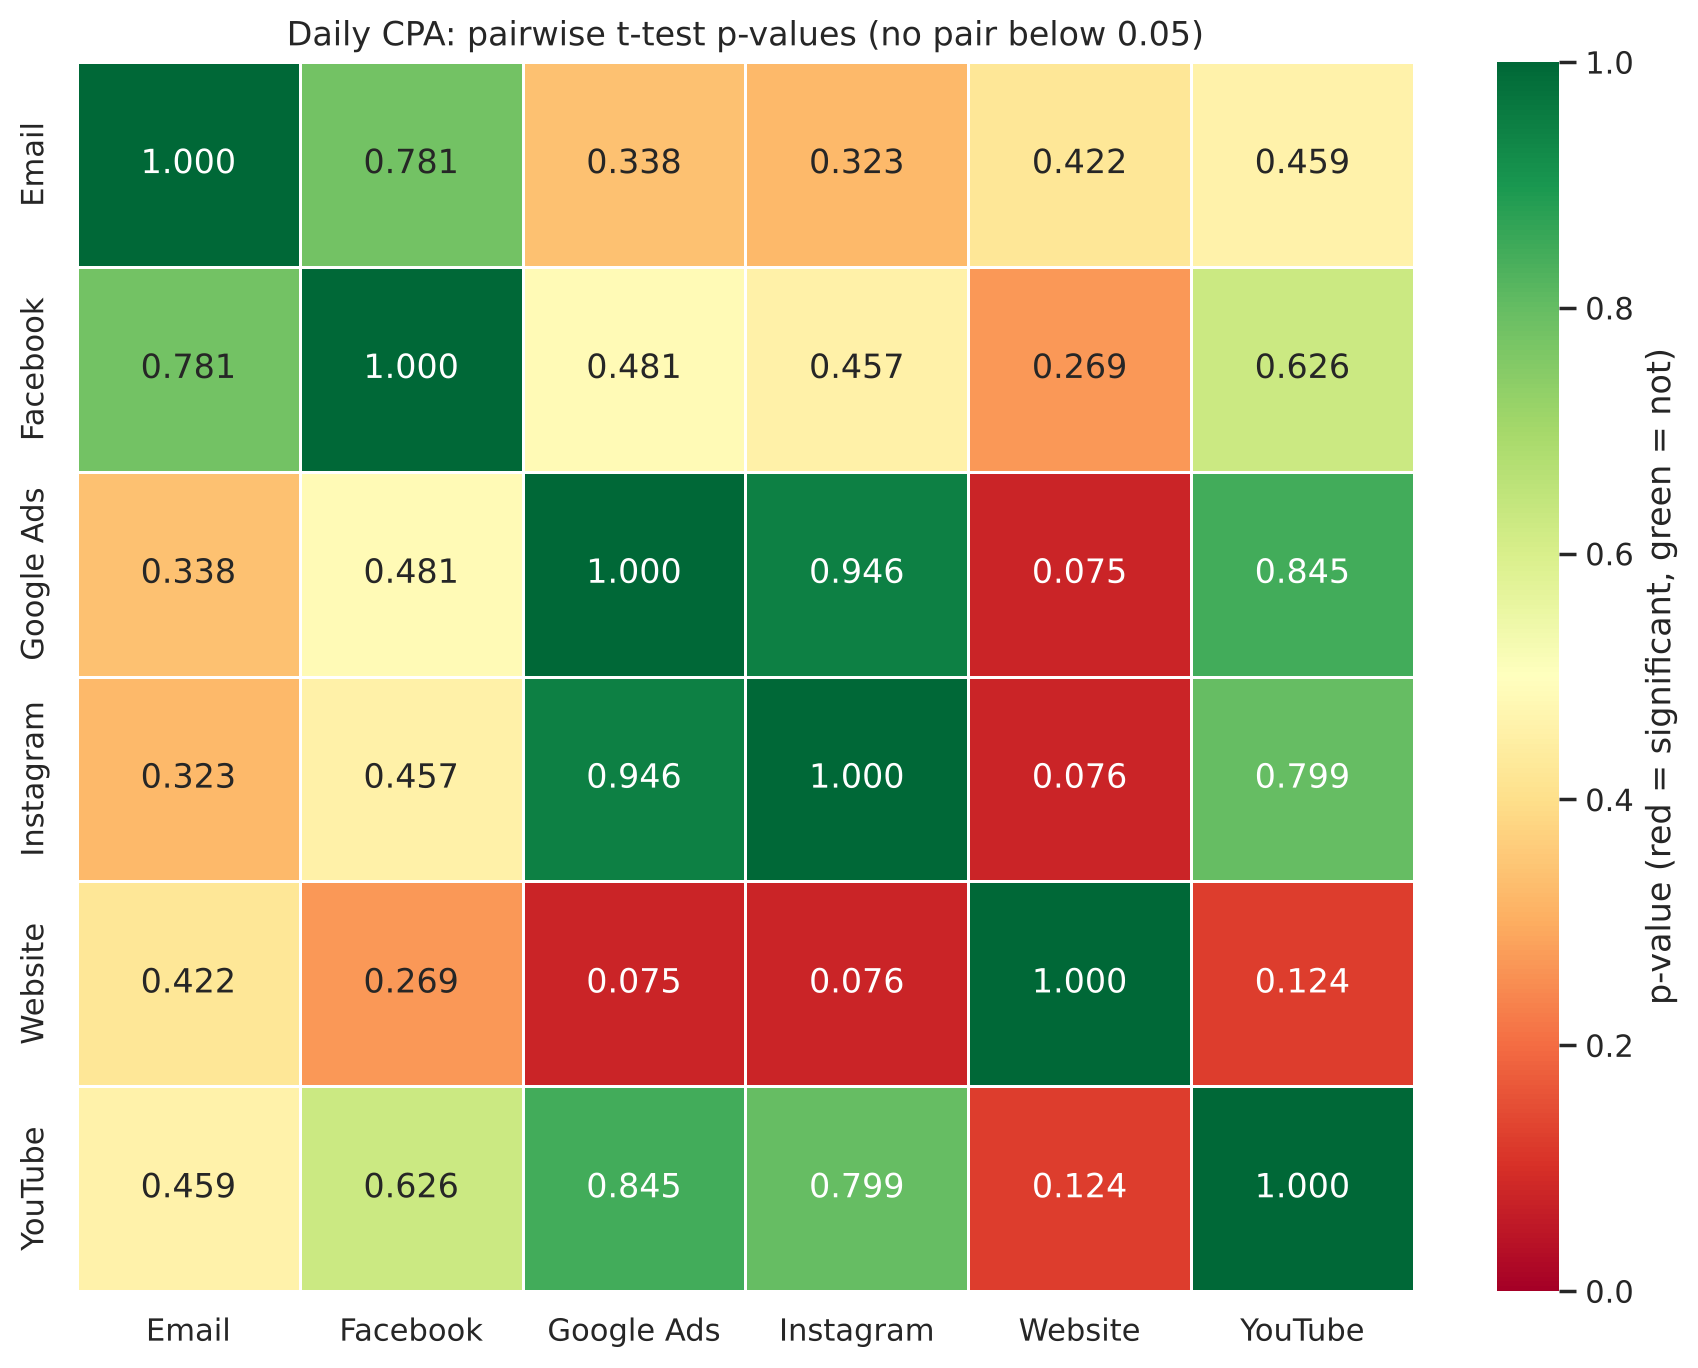

In [6]:
def p_matrix(results, groups):
    m = pd.DataFrame(1.0, index=groups, columns=groups)
    for _, r in results.iterrows():
        m.loc[r["group_a"], r["group_b"]] = r["p_value"]
        m.loc[r["group_b"], r["group_a"]] = r["p_value"]
    return m


mat = p_matrix(cpa_results, channels)
fig, ax = plt.subplots(figsize=(9, 7))
# The lab suggests 'RdYlGn_r', but that colours LOW p-values green. 'RdYlGn' gives the intended
# mapping: red = low p (significant), green = high p (not significant).
sns.heatmap(mat, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "p-value (red = significant, green = not)"}, linewidths=0.5)
ax.set_title("Daily CPA: pairwise t-test p-values (no pair below 0.05)")
fig.tight_layout()
fig.savefig(FIG / "metric_comparison_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Step 4 summary**
- **CPA:** 0 of 15 pairs significant at α = 0.05, even before correction. The smallest p-value is 0.075 (Google Ads vs Website and Instagram vs Website), for a gap of about 1.1%. Every Cohen's d is below 0.14 (negligible).
- **Daily conversion rate:** 0 of 15 pairs significant.
- **ROAS:** 2 of 15 pairs are nominally significant. Facebook beats Instagram (p = 0.006, d = 0.20, just at the edge of "small") and Email (p = 0.049, d = 0.15). With 15 tests, about 0.75 false positives are expected by chance, and neither pair survives correction in Step 6.

So on the metric the CMO cares about most, cost per acquisition, a year of daily data shows no reliable difference between channels.

## Step 5 — Fisher's exact test on conversions

In [7]:
totals = daily.groupby("channel")[["conversions", "clicks"]].sum()
totals["non_conversions"] = totals["clicks"] - totals["conversions"]
totals["conversion_rate"] = totals["conversions"] / totals["clicks"]
totals

,conversions,clicks,non_conversions,conversion_rate
channel,,,,
Email,1485425,18493963,17008538,0.0803
Facebook,1446338,18037947,16591609,0.0802
Google Ads,1468717,18340807,16872090,0.0801
Instagram,1462938,18316654,16853716,0.0799
Website,1477660,18414628,16936968,0.0802
YouTube,1463649,18350407,16886758,0.0798


In [8]:
fisher_rows = []
for a, b in pairs:
    ca, na = totals.loc[a, "conversions"], totals.loc[a, "clicks"]
    cb, nb = totals.loc[b, "conversions"], totals.loc[b, "clicks"]
    table = [[ca, na - ca], [cb, nb - cb]]
    odds_ratio, p = fisher_exact(table, alternative="two-sided")
    ra, rb = ca / na, cb / nb
    fisher_rows.append({"group_a": a, "group_b": b, "conversions_a": ca, "clicks_a": na,
                        "conversions_b": cb, "clicks_b": nb, "rate_a": ra, "rate_b": rb,
                        "difference": rb - ra, "pct_difference": (rb - ra) / ra * 100,
                        "odds_ratio": odds_ratio, "p_value": p, "significant": p < ALPHA})
    print(f"{a:>10} vs {b:<10} {ra:.4%} vs {rb:.4%}  diff {(rb - ra) * 100:+.3f} pp "
          f"({(rb - ra) / ra:+.2%})  OR={odds_ratio:.4f}  p={p:.2e}{'  *' if p < ALPHA else ''}")
fisher_results = pd.DataFrame(fisher_rows)
print(f"\nFisher's exact: {len(fisher_results)} comparisons, "
      f"{fisher_results['significant'].sum()} significant at alpha = {ALPHA}")

     Email vs Facebook   8.0319% vs 8.0183%  diff -0.014 pp (-0.17%)  OR=1.0018  p=1.29e-01
     Email vs Google Ads 8.0319% vs 8.0079%  diff -0.024 pp (-0.30%)  OR=1.0033  p=7.28e-03  *
     Email vs Instagram  8.0319% vs 7.9869%  diff -0.045 pp (-0.56%)  OR=1.0061  p=4.88e-07  *
     Email vs Website    8.0319% vs 8.0244%  diff -0.008 pp (-0.09%)  OR=1.0010  p=3.98e-01
     Email vs YouTube    8.0319% vs 7.9761%  diff -0.056 pp (-0.70%)  OR=1.0076  p=4.26e-10  *
  Facebook vs Google Ads 8.0183% vs 8.0079%  diff -0.010 pp (-0.13%)  OR=1.0014  p=2.49e-01
  Facebook vs Instagram  8.0183% vs 7.9869%  diff -0.031 pp (-0.39%)  OR=1.0043  p=4.90e-04  *
  Facebook vs Website    8.0183% vs 8.0244%  diff +0.006 pp (+0.08%)  OR=0.9992  p=5.00e-01
  Facebook vs YouTube    8.0183% vs 7.9761%  diff -0.042 pp (-0.53%)  OR=1.0058  p=2.71e-06  *
Google Ads vs Instagram  8.0079% vs 7.9869%  diff -0.021 pp (-0.26%)  OR=1.0029  p=1.92e-02  *
Google Ads vs Website    8.0079% vs 8.0244%  diff +0.016 pp (+

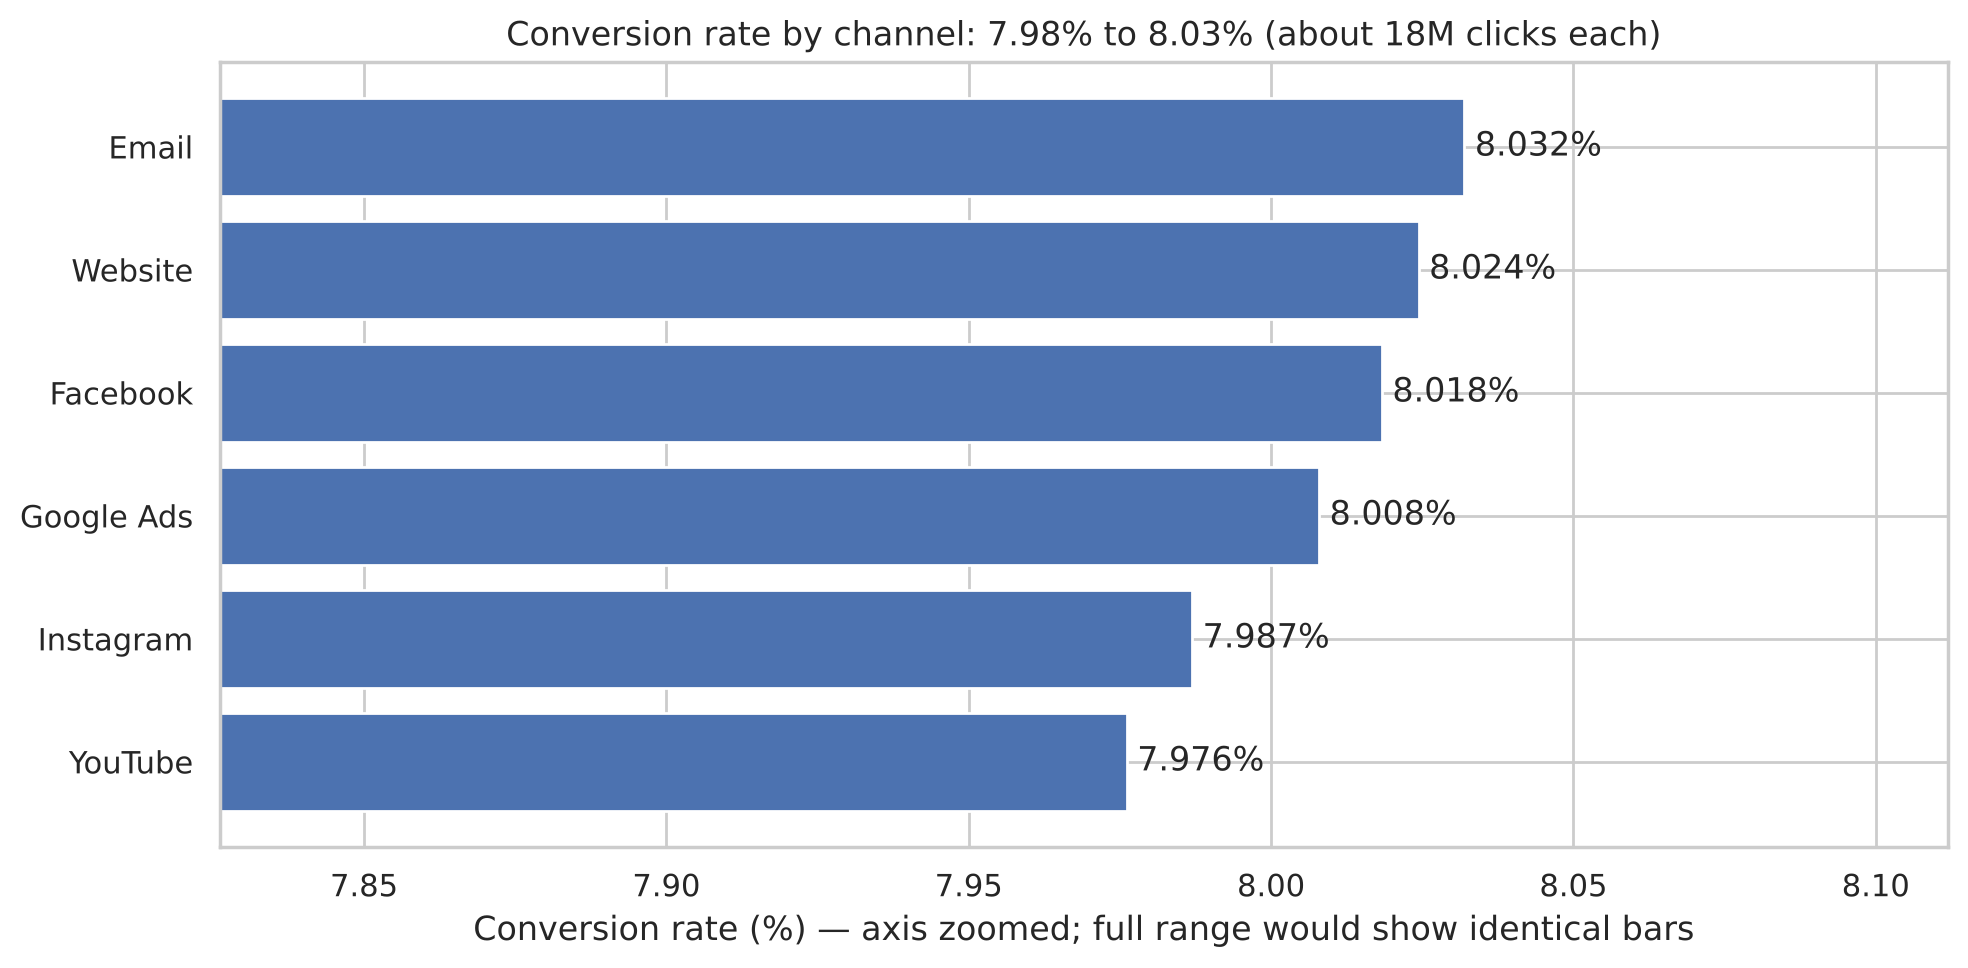

In [9]:
s = totals["conversion_rate"].sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(s.index, s.values * 100, color="#4C72B0")
for i, v in enumerate(s.values):
    ax.text(v * 100, i, f" {v:.3%}", va="center")
ax.set_xlim(s.min() * 100 - 0.15, s.max() * 100 + 0.08)
ax.set(xlabel="Conversion rate (%) — axis zoomed; full range would show identical bars",
       title="Conversion rate by channel: 7.98% to 8.03% (about 18M clicks each)")
fig.tight_layout()
fig.savefig(FIG / "rate_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Step 5 summary and key questions**

- **Which channels differ significantly?** Several pairs reach p < 0.05, mostly Email and Website (highest rates) against YouTube and Instagram (lowest).
- **Is that practically significant?** No. The largest gap, Email (8.03%) vs YouTube (7.98%), is 0.056 percentage points, about 0.7% in relative terms. Each channel has about 18 million clicks, and with that many observations Fisher's test can detect differences far too small to matter for a budget.
- **Fisher vs t-test on conversion rate:** the t-test on *daily* conversion rates found nothing, while Fisher on *pooled clicks* finds several differences. They answer different questions. Fisher treats every click as independent and asks whether the pooled rates differ at all. The t-test asks whether the rate we'd see on a typical day is reliably different. Day-to-day variation (about ±0.5 pp) is much larger than these gaps, so from a planning point of view the "significant" differences are invisible.

## Step 6 — Multiple-comparisons correction

In [10]:
n_cpa, n_cr = len(cpa_results), len(fisher_results)
total = n_cpa + n_cr
print(f"Comparisons made: {n_cpa} CPA t-tests + {n_cr} conversion-rate Fisher tests = {total}")
print(f"Expected false positives at alpha = {ALPHA} if no real differences exist: {total} x {ALPHA} = {total * ALPHA:.1f}")
print("With this many tests, one or two 'significant' results would appear by chance alone,")
print("so uncorrected p-values overstate how many channels really differ.")

Comparisons made: 15 CPA t-tests + 15 conversion-rate Fisher tests = 30
Expected false positives at alpha = 0.05 if no real differences exist: 30 x 0.05 = 1.5
With this many tests, one or two 'significant' results would appear by chance alone,
so uncorrected p-values overstate how many channels really differ.


In [11]:
def apply_corrections(res, label):
    res = res.copy()
    m = len(res)
    alpha_bonf = ALPHA / m
    res["significant_bonferroni"] = res["p_value"] < alpha_bonf
    res["p_value_fdr"] = false_discovery_control(res["p_value"].values, method="bh")
    res["significant_fdr"] = res["p_value_fdr"] < ALPHA
    print(f"{label}: Bonferroni alpha = {ALPHA}/{m} = {alpha_bonf:.5f}")
    print(f"  uncorrected significant: {res['significant'].sum()}")
    print(f"  Bonferroni significant:  {res['significant_bonferroni'].sum()}")
    print(f"  FDR (BH) significant:    {res['significant_fdr'].sum()}")
    kept = res[res["significant_fdr"]]
    for _, r in kept.iterrows():
        print(f"    {r['group_a']} vs {r['group_b']}: p = {r['p_value']:.2e}, FDR-adjusted p = {r['p_value_fdr']:.2e}"
              f"{' (also Bonferroni)' if r['significant_bonferroni'] else ''}")
    print()
    return res


cpa_results = apply_corrections(cpa_results, "CPA (t-test)")
fisher_results = apply_corrections(fisher_results, "Conversion rate (Fisher)")
cr_ttest_results = apply_corrections(cr_ttest_results, "Conversion rate (daily t-test)")
roas_results = apply_corrections(roas_results, "ROAS (t-test)")

CPA (t-test): Bonferroni alpha = 0.05/15 = 0.00333
  uncorrected significant: 0
  Bonferroni significant:  0
  FDR (BH) significant:    0

Conversion rate (Fisher): Bonferroni alpha = 0.05/15 = 0.00333
  uncorrected significant: 9
  Bonferroni significant:  7
  FDR (BH) significant:    9
    Email vs Google Ads: p = 7.28e-03, FDR-adjusted p = 1.36e-02
    Email vs Instagram: p = 4.88e-07, FDR-adjusted p = 2.44e-06 (also Bonferroni)
    Email vs YouTube: p = 4.26e-10, FDR-adjusted p = 6.39e-09 (also Bonferroni)
    Facebook vs Instagram: p = 4.90e-04, FDR-adjusted p = 1.05e-03 (also Bonferroni)
    Facebook vs YouTube: p = 2.71e-06, FDR-adjusted p = 1.02e-05 (also Bonferroni)
    Google Ads vs Instagram: p = 1.92e-02, FDR-adjusted p = 3.19e-02
    Google Ads vs YouTube: p = 3.82e-04, FDR-adjusted p = 9.54e-04 (also Bonferroni)
    Instagram vs Website: p = 2.89e-05, FDR-adjusted p = 8.68e-05 (also Bonferroni)
    Website vs YouTube: p = 6.89e-08, FDR-adjusted p = 5.17e-07 (also Bonferro

In [12]:
correction_summary = pd.DataFrame({
    "Uncorrected (alpha=0.05)": [cpa_results["significant"].sum(), fisher_results["significant"].sum()],
    "Bonferroni": [cpa_results["significant_bonferroni"].sum(), fisher_results["significant_bonferroni"].sum()],
    "FDR (Benjamini-Hochberg)": [cpa_results["significant_fdr"].sum(), fisher_results["significant_fdr"].sum()],
}, index=["CPA (t-test, 15 pairs)", "Conversion rate (Fisher, 15 pairs)"])
correction_summary.to_csv(OUT / "correction_summary.csv")
correction_summary

,Uncorrected (alpha=0.05),Bonferroni,FDR (Benjamini-Hochberg)
"CPA (t-test, 15 pairs)",0,0,0
"Conversion rate (Fisher, 15 pairs)",9,7,9


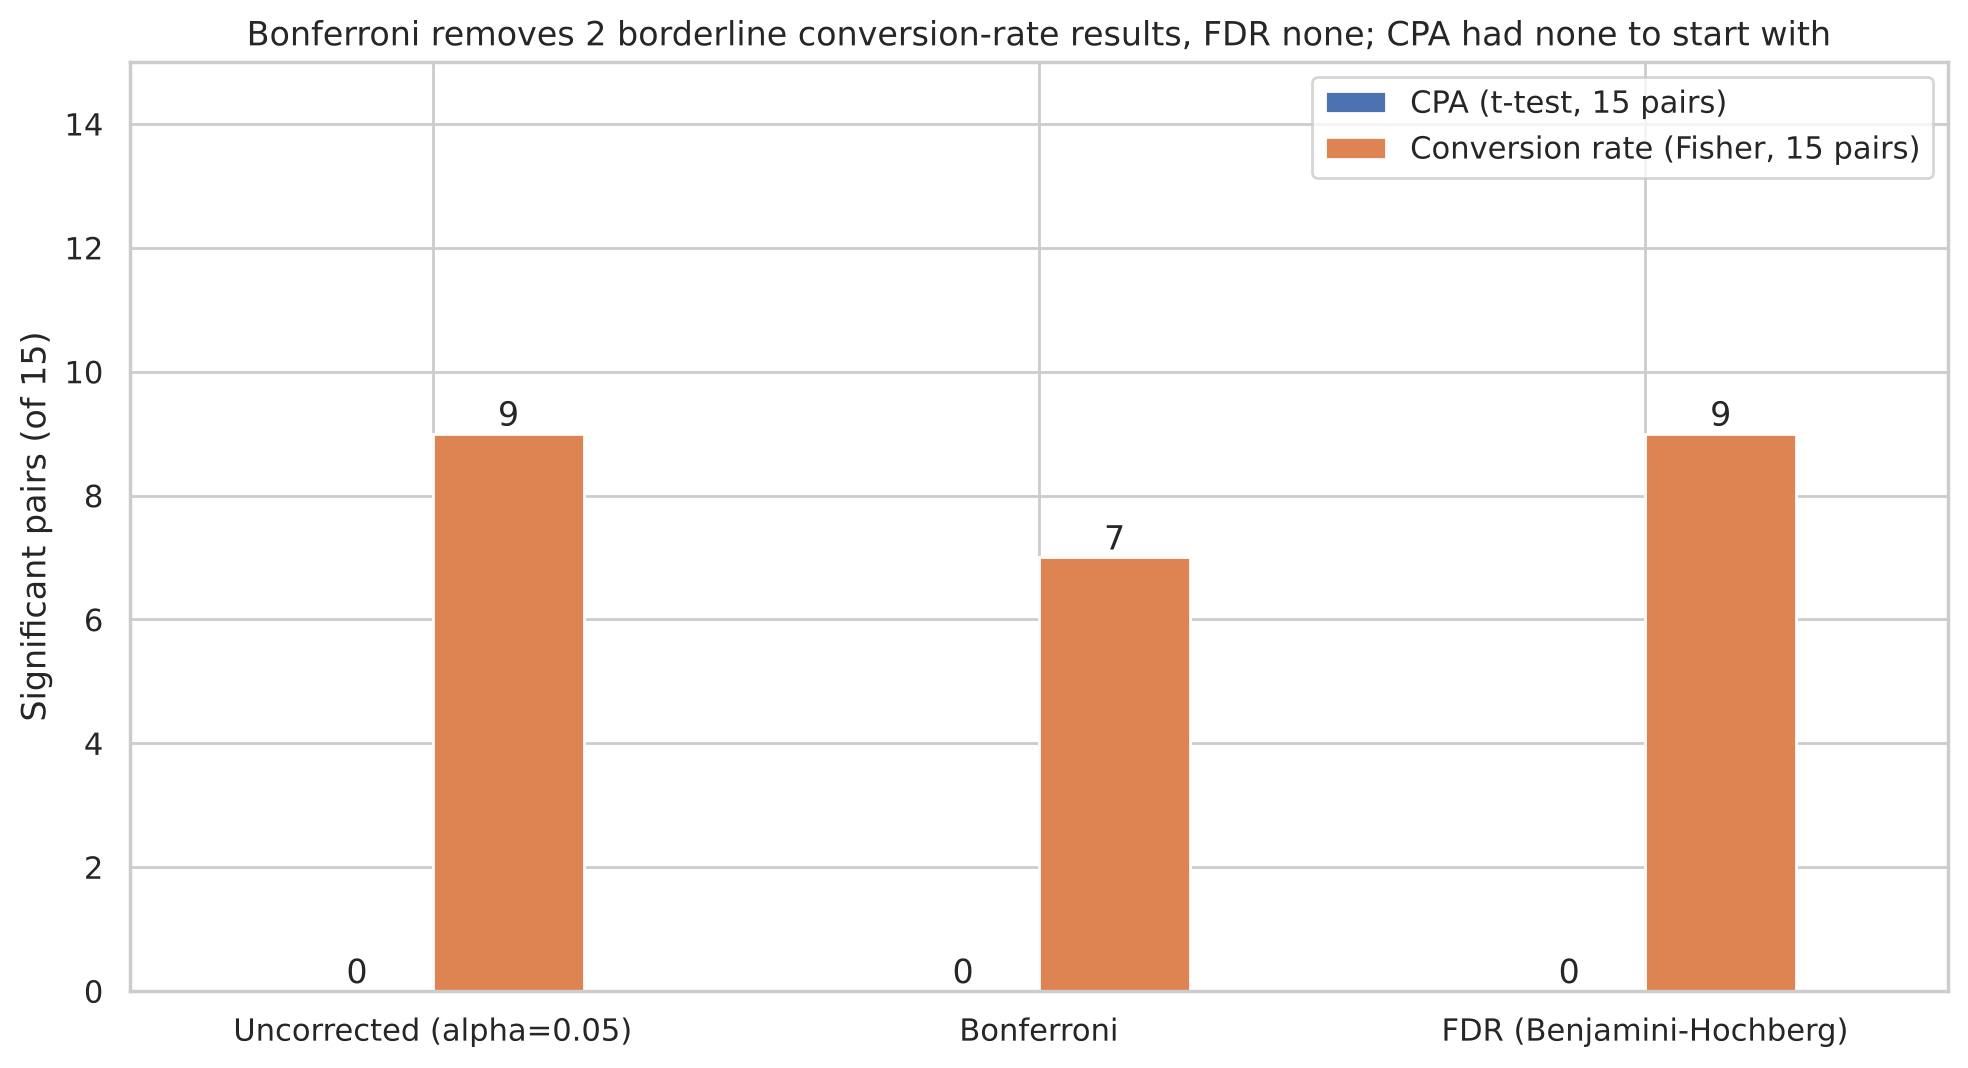

In [13]:
ax = correction_summary.T.plot(kind="bar", figsize=(10, 5.5), color=["#4C72B0", "#DD8452"], rot=0)
for c in ax.containers:
    ax.bar_label(c)
ax.set(ylabel="Significant pairs (of 15)", ylim=(0, 15),
       title="Bonferroni removes 2 borderline conversion-rate results, FDR none; CPA had none to start with")
ax.legend(title="")
plt.tight_layout()
plt.savefig(FIG / "correction_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
cpa_results.to_csv(OUT / "pairwise_cpa_ttests.csv", index=False)
cr_ttest_results.to_csv(OUT / "pairwise_conversion_rate_ttests.csv", index=False)
roas_results.to_csv(OUT / "pairwise_roas_ttests.csv", index=False)
fisher_results.to_csv(OUT / "pairwise_conversion_rate_fisher.csv", index=False)
print("Saved pairwise results to outputs/")
fisher_results[["group_a", "group_b", "rate_a", "rate_b", "difference", "p_value",
                "p_value_fdr", "significant", "significant_bonferroni", "significant_fdr"]].round(6)

Saved pairwise results to outputs/


,group_a,group_b,rate_a,rate_b,difference,p_value,p_value_fdr,significant,significant_bonferroni,significant_fdr
0,Email,Facebook,0.0803,0.0802,-0.0001,0.1294,0.1765,False,False,False
1,Email,Google Ads,0.0803,0.0801,-0.0002,0.0073,0.0136,True,False,True
2,Email,Instagram,0.0803,0.0799,-0.0004,0.0000,0.0000,True,True,True
3,Email,Website,0.0803,0.0802,-0.0001,0.3981,0.4265,False,False,False
4,Email,YouTube,0.0803,0.0798,-0.0006,0.0000,0.0000,True,True,True
5,Facebook,Google Ads,0.0802,0.0801,-0.0001,0.2487,0.2869,False,False,False
6,Facebook,Instagram,0.0802,0.0799,-0.0003,0.0005,0.0010,True,True,True
7,Facebook,Website,0.0802,0.0802,0.0001,0.5000,0.5000,False,False,False
8,Facebook,YouTube,0.0802,0.0798,-0.0004,0.0000,0.0000,True,True,True
9,Google Ads,Instagram,0.0801,0.0799,-0.0002,0.0192,0.0319,True,False,True


### Key insights (Step 6)

- **False positives:** uncorrected, 9 of the 30 tests looked significant, all of them conversion-rate Fisher tests. About 1.5 false positives were expected by chance. Bonferroni removed 2 borderline pairs (Email vs Google Ads, Google Ads vs Instagram), leaving 7. FDR kept all 9. With about 18M clicks per channel most Fisher p-values are tiny, so correction removes only the borderline cases. The 2 nominal ROAS results from Step 4 disappear under both methods.
- **Which correction fits?** For budget decisions, a false positive means moving real money to a channel that isn't better, so it's costly. **Bonferroni** is the safer gate for an actual budget move. **FDR** fits screening, where we choose which channels to test further and can accept a few false leads.
- **Practical implication:** no correction rescues CPA or ROAS, which are the metrics that decide budget. The conversion-rate differences that survive are real but tiny (≤ 0.06 pp). Correction tells us which differences are likely real. It doesn't tell us whether they are large enough to act on; that takes effect size and power (Part 4).